# Detección de fraude en tarjetas de crédito

El código carga las transacciones, describe su distribución y separa los datos
etiquetados en entrenamiento, validación y prueba. Después entrena seis detectores
de anomalías y compara sus scores sobre validación. Las transacciones con variables
idénticas permanecen juntas para evitar que sus copias contaminen la evaluación.

## 1. Configuración

`COLAB = False` indica que se trabaja con los CSV locales. Se fija la semilla en 42
para reproducir la separación. `RAIZ` localiza el repositorio desde la raíz o desde
`src`, permite importar sus funciones y mantiene las rutas de datos y resultados
independientes de la carpeta de ejecución. Las opciones de pandas y matplotlib facilitan la lectura
de las tablas y gráficas.

In [1]:
COLAB = False
SEMILLA = 42

from pathlib import Path
import sys

# Localizar la raíz tanto desde src como desde la raíz del repositorio.
RAIZ = Path.cwd().resolve()
if not (RAIZ / "datos").is_dir():
    RAIZ = RAIZ.parent
assert (RAIZ / "datos").is_dir() and (RAIZ / "src").is_dir(), "No se encuentra la raíz del repositorio."
sys.path.insert(0, str(RAIZ))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.datos import cargar_datos
from src.exploracion import (
    resumen_datasets, tabla_clases, grafico_clases,
    resumen_importes, graficos_variables,
)
from src.separacion import (
    separar_datos, resumen_particiones, comprobar_separacion, guardar_asignacion,
)

pd.options.display.max_columns = None
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams["figure.dpi"] = 110

print("Entorno local. Semilla:", SEMILLA)


Entorno local. Semilla: 42


## 2. Cargar los datos y comprobar su estructura

Cada fila representa una transacción. `X1`–`X20` y `Amount` son las **21 entradas**;
`Class` es la respuesta (0 = normal, 1 = fraude). No conocemos el significado de
`X1`–`X20`, por lo que no les atribuiremos una interpretación económica.

En producción, `Class` está vacía deliberadamente: no se rellena ni se usa como entrada.


In [2]:
df_const, df_prod = cargar_datos(RAIZ / "datos")
columnas = df_const.columns.drop("Class").tolist()
X_prod = df_prod[columnas].copy()

display(resumen_datasets(df_const, df_prod))
display(df_const.head())
print("Tipos de datos:")
display(df_const.dtypes.rename("Tipo").to_frame())


,Filas,Variables de entrada,Ausentes en variables,Etiquetas ausentes,Filas repetidas completas,Filas repetidas por variables
Dataset,,,,,,
Construcción,170884,21,0,0,4167,4167
Producción,113923,21,0,113923,2109,2109


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount,Class
0,374.000,-288.000,-150.000,-232.000,-90.000,262.000,-262.000,88.000,-26.000,152.000,212.000,60.000,98.000,-50.000,134.000,178.000,64.000,-322.000,-58.000,20.000,144.000,0
1,436.000,-202.000,-566.000,-652.000,166.000,58.000,-18.000,-0.000,54.000,-54.000,214.000,214.000,-2.000,198.000,248.000,-688.000,108.000,100.000,-34.000,-136.000,10.460,0
2,388.000,-128.000,-56.000,30.000,-114.000,104.000,-210.000,72.000,298.000,2.000,28.000,78.000,-168.000,22.000,82.000,172.000,-218.000,222.000,36.000,-40.000,31.720,0
3,-486.000,4.000,314.000,-80.000,-276.000,-94.000,-34.000,94.000,-252.000,2.000,-198.000,-24.000,116.000,8.000,138.000,-110.000,-86.000,326.000,-358.000,-182.000,134.850,0
4,258.000,-238.000,300.000,-70.000,-374.000,122.000,-350.000,92.000,134.000,94.000,4.000,-40.000,-260.000,-192.000,-382.000,182.000,120.000,-120.000,282.000,-6.000,8.700,0


Tipos de datos:


,Tipo
X1,float64
X2,float64
X3,float64
X4,float64
X5,float64
X6,float64
X7,float64
X8,float64
X9,float64
X10,float64


**Cómo leer la tabla:** construcción tiene 170.884 filas y producción 113.923.
No hay ausentes en las entradas. Los 113.923 ausentes de `Class` en producción son
esperados porque las etiquetas están ocultas.

Hay **4.167 filas repetidas en construcción y 2.109 en producción**. Este recuento
cuenta las copias posteriores a la primera aparición; no es el número de grupos
ni el total de filas que participan en repeticiones. No eliminamos ninguna:
en construcción mantendremos cada grupo en una sola partición y en producción
conservaremos el número de filas y el orden necesarios para la futura entrega.


## 3. Entender el desbalance

El recuento global ayuda a diseñar las particiones. La exploración posterior de
variables por clase se hará solo con entrenamiento.


,Transacciones,Porcentaje
Normal (0),170589,99.827
Fraude (1),295,0.173


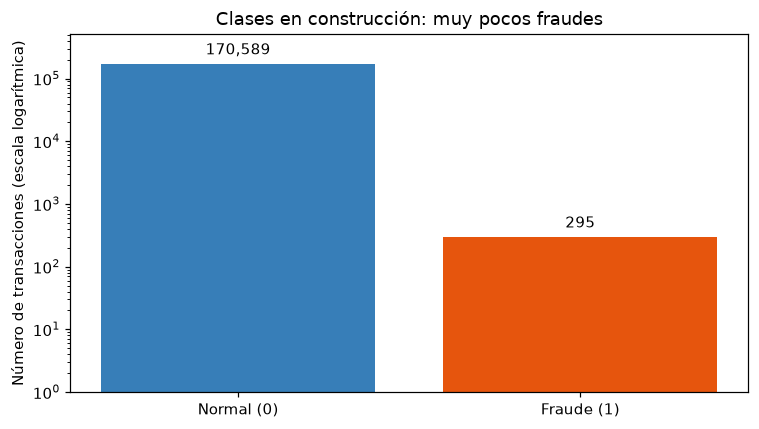

Predecir siempre 'normal' acertaría el 99.827% de las filas,
pero no detectaría ningún fraude. Por eso no elegiremos modelos por accuracy.


In [3]:
display(tabla_clases(df_const))
grafico_clases(df_const)
plt.show()

porcentaje_normal = 100 * df_const["Class"].eq(0).mean()
print(f"Predecir siempre 'normal' acertaría el {porcentaje_normal:.3f}% de las filas,")
print("pero no detectaría ningún fraude. Por eso no elegiremos modelos por accuracy.")


**Interpretación:** solo hay 295 fraudes (aproximadamente 0,173 %).
La gráfica utiliza una escala logarítmica para que se vea también la clase minoritaria:
la altura de las barras no representa una proporción lineal.

Evaluaremos los futuros scores mediante `average_precision_score`: un valor alto
indica que los fraudes tienden a quedar en las primeras posiciones de la ordenación.
Con tan pocos positivos, diferencias pequeñas entre modelos pueden ser inestables.


## 4. Separar construcción sin compartir transacciones idénticas

Usamos **cinco particiones estratificadas por grupos**, con semilla fija:
tres forman entrenamiento, una validación y otra prueba. El reparto es aproximadamente
60/20/20; las restricciones de grupos impiden garantizar porcentajes exactos.

Un grupo se define por la coincidencia exacta de las **21 variables**, sin incluir
`Class`. Se comprueba que no haya etiquetas contradictorias dentro del mismo grupo.
`StratifiedGroupKFold` intenta mantener una proporción parecida de fraudes, respetando
los grupos. Esto evita cruces de duplicados exactos; sin identificadores de tarjeta
ni fechas no podemos garantizar independencia por cliente o por tiempo.

- **Entrenamiento:** aprender modelos y transformaciones.
- **Validación:** comparar modelos y ajustar parámetros.
- **Prueba:** evaluar una sola vez cuando la elección está cerrada.
- **Producción:** solo recibir scores al final; no participa en esta separación.


In [4]:
particiones, asignacion = separar_datos(df_const, semilla=SEMILLA)
df_train = particiones["entrenamiento"]
df_valid = particiones["validacion"]
df_test = particiones["prueba"]

display(resumen_particiones(particiones))
display(comprobar_separacion(asignacion))

ruta_particiones = guardar_asignacion(asignacion, RAIZ / "resultados" / "particiones.csv")
print("Asignación guardada en:", ruta_particiones)
print("Cada fila original está asignada una sola vez y ningún grupo cruza particiones.")


,Filas,% del total,Normales,Fraudes,% fraude
Partición,,,,,
entrenamiento,102530,60.000,102353,177,0.173
validacion,34177,20.000,34118,59,0.173
prueba,34177,20.000,34118,59,0.173


,Filas compartidas,Grupos compartidos
Comparación,,
entrenamiento / validacion,0,0
entrenamiento / prueba,0,0
validacion / prueba,0,0


Asignación guardada en: C:\Users\Natalia\workplace\Taller-Anomalias\resultados\particiones.csv
Cada fila original está asignada una sola vez y ningún grupo cruza particiones.


**Cómo leer estas tablas:** compara `% del total` con 60/20/20 y `% fraude` con
el 0,173 % global. La columna `Fraudes` muestra cuántos casos positivos sostendrán
cada evaluación. Todas las intersecciones de filas y grupos deben valer **cero**.

`guardar_asignacion` escribe en `resultados/particiones.csv` la posición de cada fila
original (empezando en cero, sin contar la cabecera), su grupo y su partición.
Así se puede reutilizar la misma separación sin modificar ni reordenar los datos.
La función sobrescribe el archivo al ejecutarse de nuevo.

Las variables `X` contienen las 21 entradas y las variables `y` contienen `Class`
convertida a entero. Las comprobaciones verifican que la etiqueta no sea una entrada,
que las columnas coincidan y que se conserven todas las filas y el orden de producción.

In [5]:
X_train = df_train[columnas].copy()
y_train = df_train["Class"].astype(int)
X_valid = df_valid[columnas].copy()
y_valid = df_valid["Class"].astype(int)
X_test = df_test[columnas].copy()
y_test = df_test["Class"].astype(int)

assert "Class" not in X_train.columns
assert list(X_train.columns) == list(X_valid.columns) == list(X_test.columns) == list(X_prod.columns)
assert X_prod.index.equals(df_prod.index)
assert len(X_train) + len(X_valid) + len(X_test) == len(df_const)
print("Entradas y etiquetas separadas. Producción conserva todas sus filas y su orden.")


Entradas y etiquetas separadas. Producción conserva todas sus filas y su orden.


## 5. Exploración de variables: solo entrenamiento

Observamos el importe y tres variables elegidas de antemano (`X1`, `X2`, `X3`).
No seleccionamos variables mirando el resultado en validación o prueba.


Estadísticas de las 21 variables en entrenamiento:


,count,mean,std,min,25%,50%,75%,max
X1,"102,530.000",1.024,389.135,"-11,282.000",-184.000,4.000,264.000,490.000
X2,"102,530.000",-0.683,333.685,"-14,544.000",-120.000,14.000,162.000,"4,294.000"
X3,"102,530.000",0.816,300.617,"-6,594.000",-178.000,36.000,206.000,"1,876.000"
X4,"102,530.000",-0.667,283.594,"-1,084.000",-170.000,-4.000,148.000,"3,344.000"
X5,"102,530.000",0.435,273.112,"-5,550.000",-138.000,-12.000,122.000,"6,960.000"
X6,"102,530.000",-0.977,264.382,"-5,232.000",-154.000,-54.000,80.000,"3,614.000"
X7,"102,530.000",-0.007,241.413,"-8,302.000",-110.000,8.000,114.000,"5,700.000"
X8,"102,530.000",-0.975,238.971,"-10,188.000",-42.000,4.000,66.000,"3,834.000"
X9,"102,530.000",-0.512,218.822,"-2,686.000",-128.000,-10.000,118.000,"3,118.000"
X10,"102,530.000",0.171,216.393,"-4,880.000",-106.000,-18.000,92.000,"4,750.000"


Importes por clase en entrenamiento:


,count,mean,std,min,50%,90%,99%,max
Class,,,,,,,,
Normal,"102,353.000",132.623,369.978,0.000,33.450,304.864,"1,521.611","29,484.800"
Fraude,177.000,203.889,433.247,0.000,18.460,540.664,"2,235.583","3,188.800"


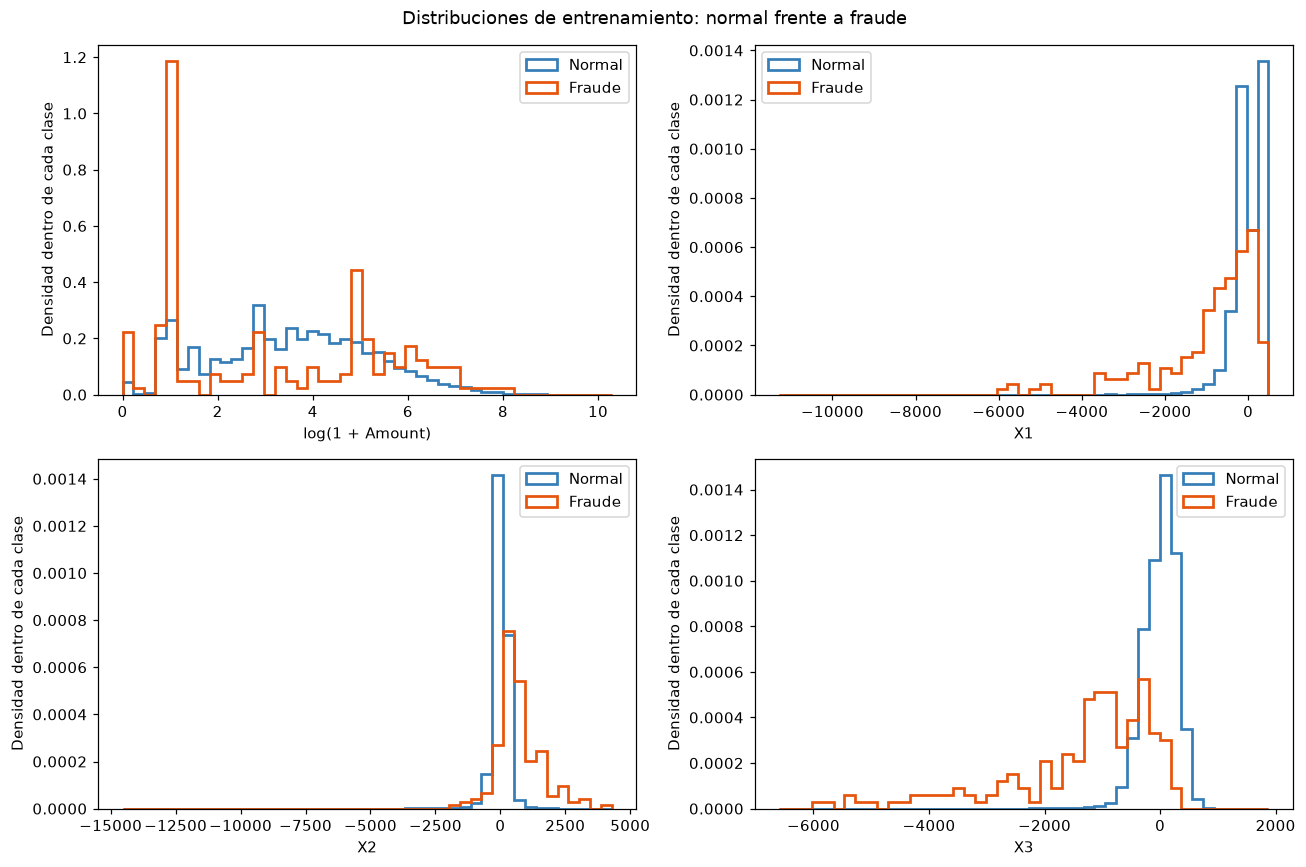

In [6]:
print("Estadísticas de las 21 variables en entrenamiento:")
display(X_train.describe().T)
print("Importes por clase en entrenamiento:")
display(resumen_importes(df_train))
graficos_variables(df_train)
plt.show()


**Cómo interpretar estos resultados:**

- En la tabla de importes, compara la mediana (`50%`) con la media (`mean`) y los
  percentiles `90%` y `99%`. Una media muy superior a la mediana indica que unos
  pocos importes grandes influyen mucho en el promedio.
- El importe se dibuja como `log(1 + Amount)` para ver mejor valores pequeños y
  grandes, incluyendo ceros. Es únicamente una transformación para el gráfico:
  **los datos de los modelos siguen sin transformar**.
- Cada histograma está normalizado dentro de su clase. Las curvas comparan formas
  de distribución, no el número de fraudes. Que una curva naranja sea alta en una
  zona no significa directamente que una transacción de esa zona sea probablemente fraude.
- El solapamiento indica que una sola variable no separa perfectamente las clases.
  Los extremos pueden contener información útil: no los eliminamos automáticamente.
- Las curvas de fraude proceden de pocos ejemplos; no debemos interpretar cada pico
  como un patrón estable. El siguiente paso será contrastar estas ideas con modelos.


## 6. Detección de anomalías: protocolo común

Los seis métodos aprenden cómo son las transacciones normales y asignan un score
a transacciones nuevas. Usamos `Class` para seleccionar normales de entrenamiento:
es un enfoque **de aprendizaje de la normalidad con etiquetas**, no completamente
no supervisado. Una anomalía estadística no tiene por qué ser un fraude.

Para esta primera comparación tomamos una muestra reproducible de hasta **20.000
normales**, sin reemplazo, del entrenamiento. Todos los modelos reciben exactamente
las mismas filas. Esto limita el coste de vecinos y mezclas gaussianas en local;
los resultados corresponden a esta muestra, no al entrenamiento con todas las filas.
Se mantienen las repeticiones que existan dentro de entrenamiento.

`StandardScaler` se ajusta solo con esa muestra. El escalado evita que las variables
con mayor dispersión dominen las distancias y los errores de reconstrucción.
Validación se transforma con el mismo escalador, sin volver a ajustarlo.
No se utilizan `X_test`, `y_test` ni producción para entrenar, elegir parámetros o comparar.

Las configuraciones son puntos de partida fijados antes de observar resultados.
La métrica principal es **average precision (AP)**, calculada con la función del
notebook original; no se sustituye por una integración trapezoidal de la curva PR.
ROC AUC es complementaria. También contamos cuántos fraudes aparecen entre las
100 transacciones con mayor score, un presupuesto ilustrativo de revisión.

In [7]:
from src.modelos_anomalias import preparar_anomalias, entrenar_detector
from src.evaluacion_anomalias import (
    evaluar_detector, graficar_detector, comparar_detectores,
    graficar_comparacion, guardar_comparacion,
)

MAX_NORMALES = 20_000
Z_train, Z_valid, escalador_anomalias, indices_normales = preparar_anomalias(
    X_train, y_train, X_valid, max_normales=MAX_NORMALES, semilla=SEMILLA,
)
resultados_anomalias = {}
print(f"Entrenamiento común: {len(Z_train):,} transacciones normales.")
print(f"Validación: {len(Z_valid):,} transacciones, {int(y_valid.sum())} fraudes.")
print(f"Referencia de AP para un score constante: {y_valid.mean():.6f}")

Entrenamiento común: 20,000 transacciones normales.
Validación: 34,177 transacciones, 59 fraudes.
Referencia de AP para un score constante: 0.001726


### 6.1. Distancia de Mahalanobis

Referencia: `AD_Distancias_clase.ipynb` y las diapositivas de distancias.

Mide cuánto se aleja una transacción del centro de las normales considerando las
correlaciones entre variables. Se utiliza `LedoitWolf` para estabilizar la estimación
de la covarianza, una adaptación del concepto de clase. El score es la distancia
al cuadrado: valores grandes indican mayor anomalía. Resume la normalidad mediante
un solo centro, por lo que puede fallar si hay varios patrones normales distintos.

La tabla muestra AP, ROC AUC y detección entre las 100 primeras posiciones.
La curva precisión-recall muestra el compromiso al ampliar las alertas. El diagrama
de cajas compara mediana y dispersión de los scores por clase; oculta los extremos
solo en el gráfico, sin quitarlos de la evaluación.

,Modelo,AP validación,ROC AUC,Revisadas,Fraudes top-k,Precisión top-k,Recall top-k,Entrenamiento (s),Scores (s)
0,Mahalanobis,0.475,0.945,100,34,0.340,0.576,0.006,0.006


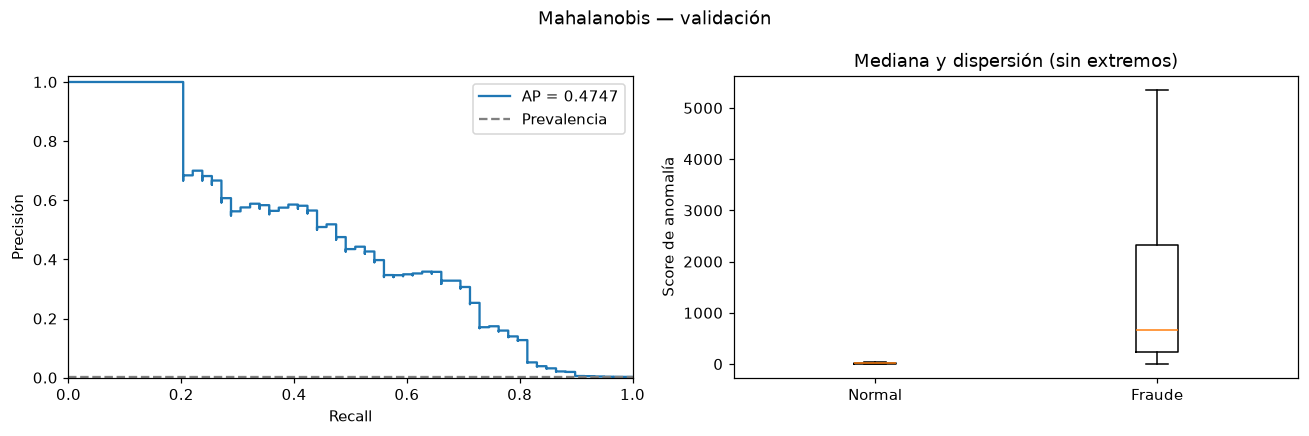

In [8]:
resultado = entrenar_detector("Mahalanobis", Z_train, Z_valid, semilla=SEMILLA)
resultados_anomalias["Mahalanobis"] = resultado
display(pd.DataFrame([evaluar_detector(resultado, y_valid)]))
graficar_detector(resultado, y_valid)
plt.show()

### 6.2. Error de reconstrucción con PCA

Referencia: `AD_reconstruccion_clase.ipynb`.

PCA comprime las 21 variables escaladas a 10 componentes y reconstruye las entradas.
El score es el error cuadrático medio de reconstrucción por transacción. Si una fila
no sigue las relaciones aprendidas en las normales, puede reconstruirse peor.
Diez componentes es una configuración inicial, no un óptimo demostrado. Una anomalía
que siga el subespacio aprendido puede tener poco error.

La tabla muestra AP, ROC AUC y detección entre las 100 primeras posiciones.
La curva precisión-recall muestra el compromiso al ampliar las alertas. El diagrama
de cajas compara mediana y dispersión de los scores por clase; oculta los extremos
solo en el gráfico, sin quitarlos de la evaluación.

,Modelo,AP validación,ROC AUC,Revisadas,Fraudes top-k,Precisión top-k,Recall top-k,Entrenamiento (s),Scores (s)
0,PCA,0.370,0.947,100,28,0.280,0.475,0.009,0.011


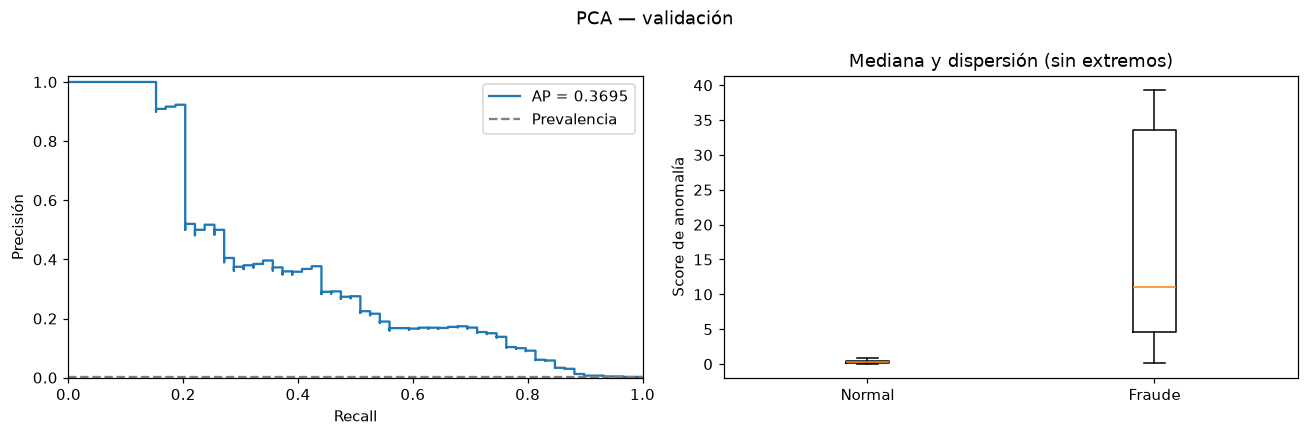

In [9]:
resultado = entrenar_detector("PCA", Z_train, Z_valid, semilla=SEMILLA)
resultados_anomalias["PCA"] = resultado
display(pd.DataFrame([evaluar_detector(resultado, y_valid)]))
graficar_detector(resultado, y_valid)
plt.show()

### 6.3. Isolation Forest

Referencia: `AD_Tools_Sklearn_clase.ipynb`.

Los árboles aíslan observaciones mediante cortes aleatorios. Las observaciones
que se aíslan fácilmente resultan más anómalas. Utilizamos 200 árboles y 256 muestras
por árbol, ampliando el ejemplo de 10 árboles para esta primera configuración.
El score es `-score_samples`: se invierte el signo porque sklearn asigna valores
más pequeños a las anomalías. No usamos `predict`, ya que necesitamos una ordenación.

La tabla muestra AP, ROC AUC y detección entre las 100 primeras posiciones.
La curva precisión-recall muestra el compromiso al ampliar las alertas. El diagrama
de cajas compara mediana y dispersión de los scores por clase; oculta los extremos
solo en el gráfico, sin quitarlos de la evaluación.

,Modelo,AP validación,ROC AUC,Revisadas,Fraudes top-k,Precisión top-k,Recall top-k,Entrenamiento (s),Scores (s)
0,Isolation Forest,0.166,0.941,100,18,0.180,0.305,0.335,0.226


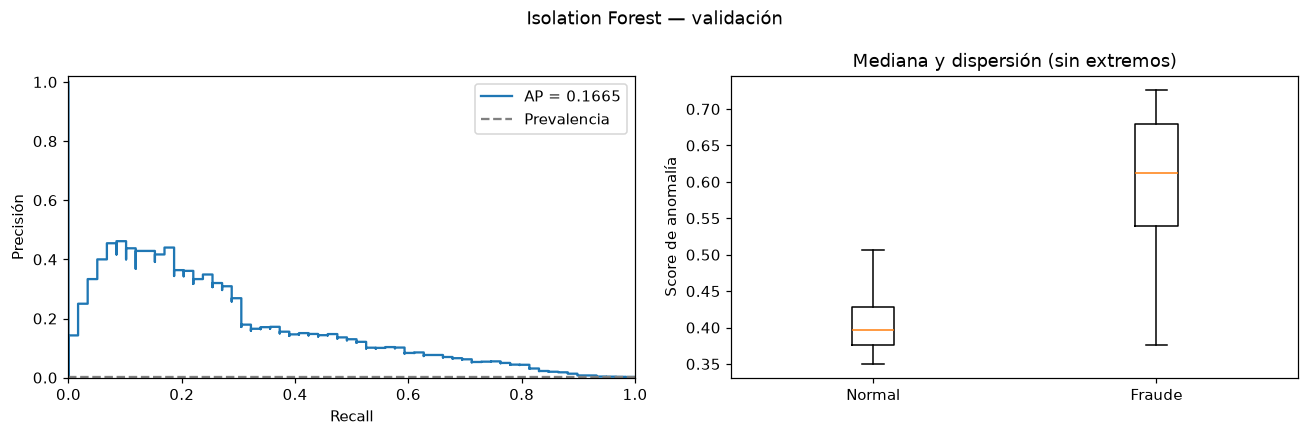

In [10]:
resultado = entrenar_detector("Isolation Forest", Z_train, Z_valid, semilla=SEMILLA)
resultados_anomalias["Isolation Forest"] = resultado
display(pd.DataFrame([evaluar_detector(resultado, y_valid)]))
graficar_detector(resultado, y_valid)
plt.show()

### 6.4. Mezcla de gaussianas (GMM)

Referencia: `AD_Tools_Sklearn_clase.ipynb` y `AD_Probabilidad_clase.ipynb`.

Ajustamos cuatro componentes gaussianas con covarianza completa para representar
varios patrones de normalidad. El score es el negativo del logaritmo de la densidad:
una observación poco compatible con el modelo recibe un score alto. Esta densidad
no es una probabilidad de fraude. Se regulariza la covarianza y se comprueba que
el ajuste converja antes de incluirlo en la comparación.

La tabla muestra AP, ROC AUC y detección entre las 100 primeras posiciones.
La curva precisión-recall muestra el compromiso al ampliar las alertas. El diagrama
de cajas compara mediana y dispersión de los scores por clase; oculta los extremos
solo en el gráfico, sin quitarlos de la evaluación.

,Modelo,AP validación,ROC AUC,Revisadas,Fraudes top-k,Precisión top-k,Recall top-k,Entrenamiento (s),Scores (s)
0,GMM,0.579,0.933,100,44,0.440,0.746,0.819,0.031


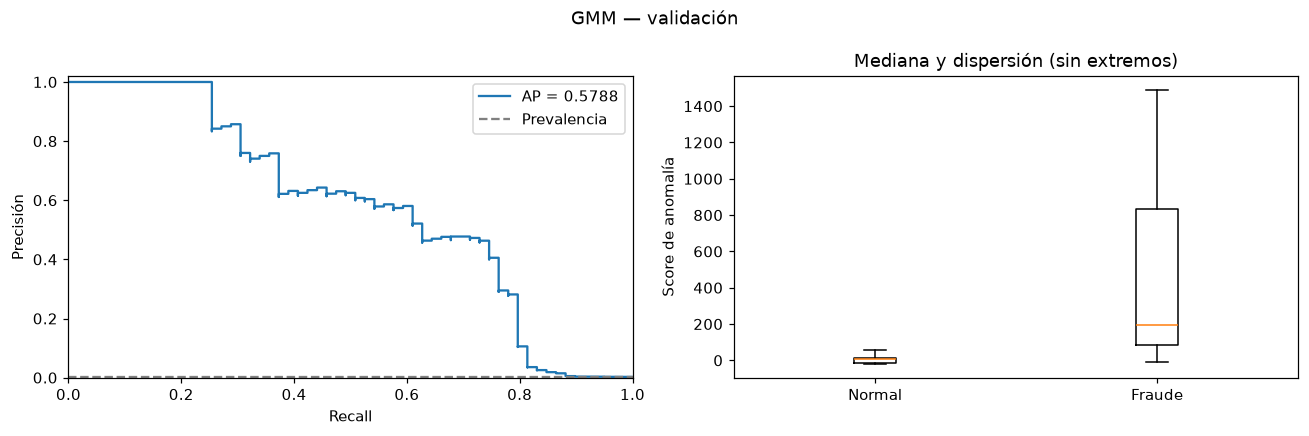

In [11]:
resultado = entrenar_detector("GMM", Z_train, Z_valid, semilla=SEMILLA)
resultados_anomalias["GMM"] = resultado
display(pd.DataFrame([evaluar_detector(resultado, y_valid)]))
graficar_detector(resultado, y_valid)
plt.show()

### 6.5. Local Outlier Factor (LOF)

Referencia: `AD_Tools_Sklearn_clase.ipynb`.

LOF compara la densidad de cada punto con la de sus 20 vecinos. Un punto en una zona
menos densa que su entorno puede ser anómalo. Adaptamos el ejemplo con `novelty=True`
para puntuar transacciones nuevas de validación; no se ejecuta `fit_predict` sobre
validación ni se reajusta allí. El score es `-score_samples`. Las repeticiones de
entrenamiento pueden influir en las densidades locales y los empates.

La tabla muestra AP, ROC AUC y detección entre las 100 primeras posiciones.
La curva precisión-recall muestra el compromiso al ampliar las alertas. El diagrama
de cajas compara mediana y dispersión de los scores por clase; oculta los extremos
solo en el gráfico, sin quitarlos de la evaluación.

,Modelo,AP validación,ROC AUC,Revisadas,Fraudes top-k,Precisión top-k,Recall top-k,Entrenamiento (s),Scores (s)
0,LOF,0.595,0.953,100,47,0.470,0.797,0.322,0.488


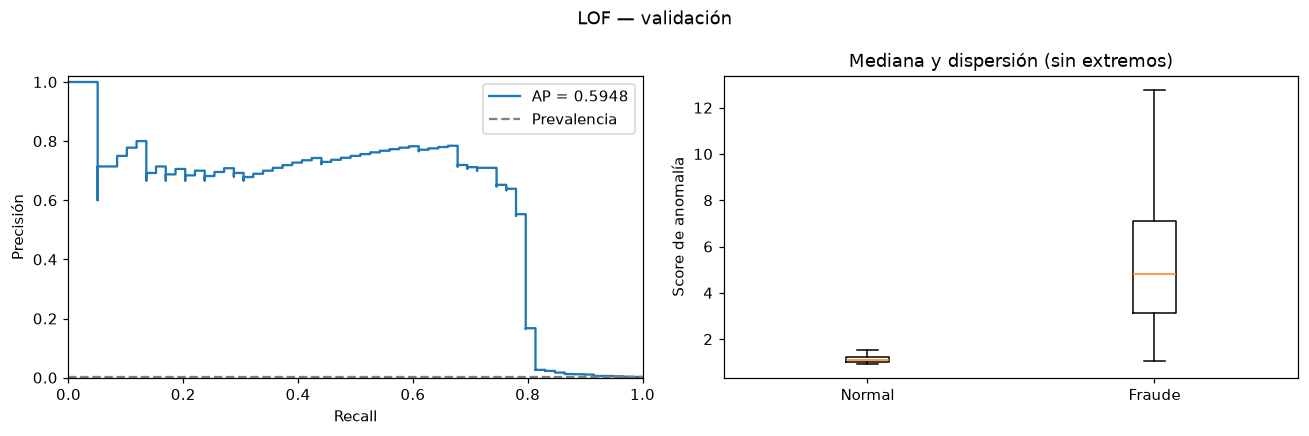

In [12]:
resultado = entrenar_detector("LOF", Z_train, Z_valid, semilla=SEMILLA)
resultados_anomalias["LOF"] = resultado
display(pd.DataFrame([evaluar_detector(resultado, y_valid)]))
graficar_detector(resultado, y_valid)
plt.show()

### 6.6. Distancia al centroide más cercano

Referencia: sección de K-means y cuantización vectorial de `Deteccion_de_anomalias.pdf`.

Aprendemos ocho centroides de transacciones normales, con diez inicializaciones.
El score es la distancia euclídea al centroide más cercano en el espacio escalado.
Los puntos alejados de todos los grupos reciben scores altos. Este criterio supone
que la distancia a esos centros describe bien la normalidad; puede funcionar peor
cuando los grupos tienen formas o dispersiones muy distintas.

La tabla muestra AP, ROC AUC y detección entre las 100 primeras posiciones.
La curva precisión-recall muestra el compromiso al ampliar las alertas. El diagrama
de cajas compara mediana y dispersión de los scores por clase; oculta los extremos
solo en el gráfico, sin quitarlos de la evaluación.

,Modelo,AP validación,ROC AUC,Revisadas,Fraudes top-k,Precisión top-k,Recall top-k,Entrenamiento (s),Scores (s)
0,K-means,0.268,0.946,100,26,0.260,0.441,0.203,0.012


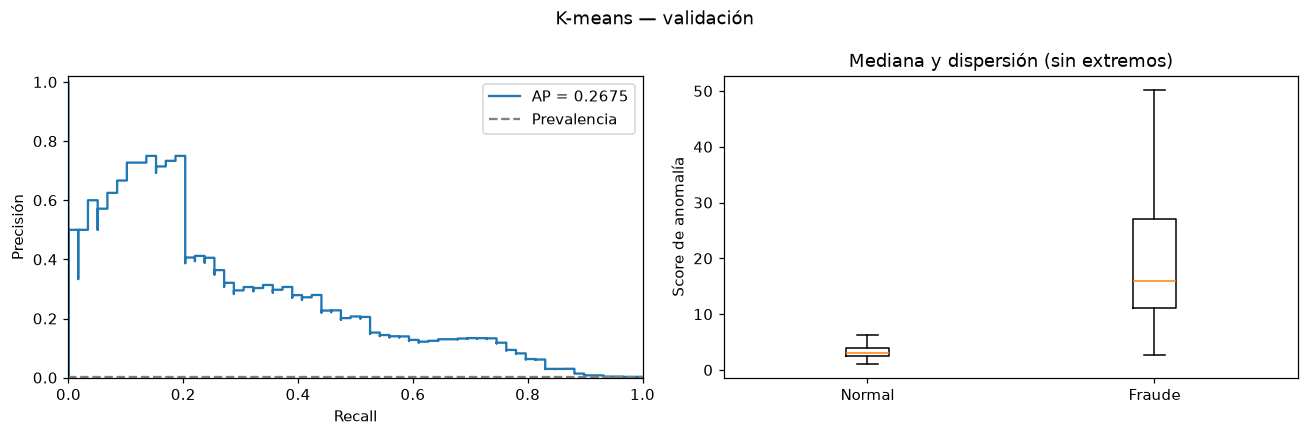

In [13]:
resultado = entrenar_detector("K-means", Z_train, Z_valid, semilla=SEMILLA)
resultados_anomalias["K-means"] = resultado
display(pd.DataFrame([evaluar_detector(resultado, y_valid)]))
graficar_detector(resultado, y_valid)
plt.show()

## 7. Comparación de los detectores

Ordenamos los resultados por AP de validación, de mayor a menor. Todos los modelos
se evalúan sobre las mismas filas, sin equilibrar la validación y con scores altos
para mayor anomalía. Los valores absolutos de los scores tienen escalas distintas:
no se comparan ni se promedian directamente entre métodos.

`Precisión top-k` indica la proporción de fraudes entre las 100 alertas y `Recall top-k`
qué fracción de los 59 fraudes se ha encontrado. Los empates se resuelven conservando
el orden original de validación. Los tiempos excluyen la carga, el escalado y las gráficas.

El primer puesto identifica el mejor de **estos experimentos** en esta validación.
No demuestra que sea el mejor algoritmo en general, y con 59 positivos pequeñas
diferencias pueden cambiar en otras particiones. No evaluamos prueba todavía.

,Modelo,AP validación,ROC AUC,Revisadas,Fraudes top-k,Precisión top-k,Recall top-k,Entrenamiento (s),Scores (s)
0,LOF,0.595,0.953,100,47,0.470,0.797,0.322,0.488
1,GMM,0.579,0.933,100,44,0.440,0.746,0.819,0.031
2,Mahalanobis,0.475,0.945,100,34,0.340,0.576,0.006,0.006
3,PCA,0.370,0.947,100,28,0.280,0.475,0.009,0.011
4,K-means,0.268,0.946,100,26,0.260,0.441,0.203,0.012
5,Isolation Forest,0.166,0.941,100,18,0.180,0.305,0.335,0.226


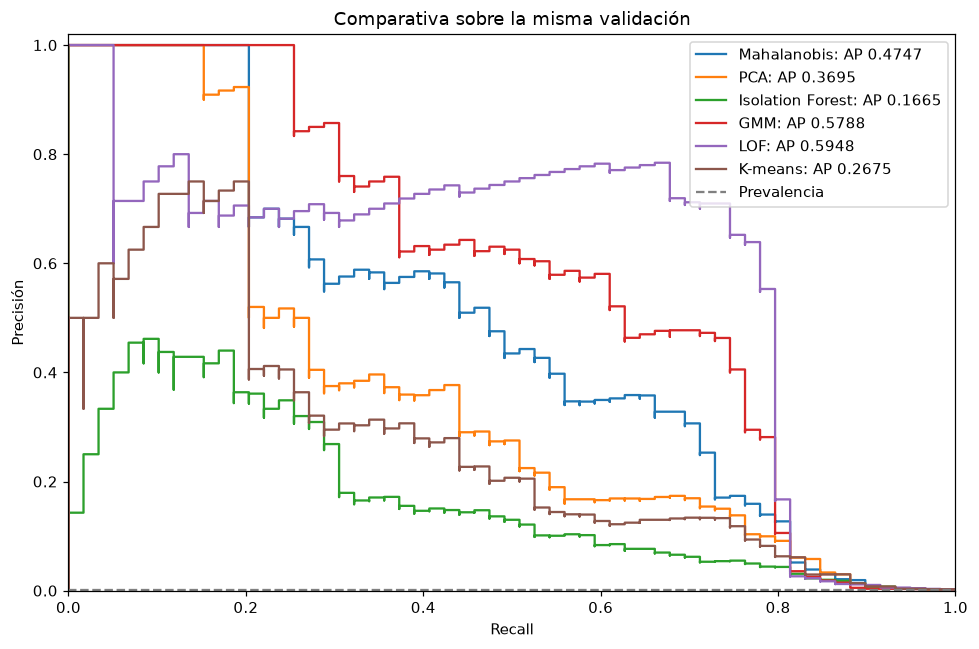

Mayor AP en esta validación: LOF (0.5948).
Es un resultado de las configuraciones iniciales, pendiente de confirmar su estabilidad.


Métricas, scores de validación, muestra y configuraciones guardados en resultados/.


In [14]:
comparacion = comparar_detectores(resultados_anomalias, y_valid)
display(comparacion)
graficar_comparacion(resultados_anomalias, y_valid)
plt.show()

mejor = comparacion.iloc[0]
print(f"Mayor AP en esta validación: {mejor['Modelo']} ({mejor['AP validación']:.4f}).")
print("Es un resultado de las configuraciones iniciales, pendiente de confirmar su estabilidad.")
guardar_comparacion(
    resultados_anomalias, y_valid, indices_normales, SEMILLA, RAIZ / "resultados",
)
print("Métricas, scores de validación, muestra y configuraciones guardados en resultados/.")

**Alcance de la comparación.** Se implementan los métodos clásicos anteriores.
DBSCAN, presente en clase, asigna grupos/ruido a los datos ajustados y no ofrece
directamente un score continuo para transacciones nuevas; incorporarlo requeriría
definir y justificar otra regla. ECOD de PyOD, RBIG y los autoencoders quedan fuera
de esta primera ronda. Los ejemplos convolucionales y U-Net trabajan con imágenes
 y necesitarían una adaptación distinta a estos datos tabulares.

Los archivos guardados registran resultados de validación y la configuración exacta;
no contienen predicciones de producción. Los scores conservan el identificador de
fila original para poder comprobar su correspondencia con las etiquetas.

### Interpretación de la ejecución guardada

Con la semilla 42 y la muestra común de 20.000 normales, **LOF obtiene AP = 0,5948**
y **GMM AP = 0,5788**. Son los dos mejores en esta validación, pero la diferencia de
aproximadamente 0,016 de AP no basta para afirmar que LOF sea superior de forma estable.
Entre las 100 primeras alertas, LOF encuentra 47 de los 59 fraudes (recall 79,7 %)
y GMM encuentra 44 (74,6 %). Eso también implica 53 y 56 falsas alertas, respectivamente.

Mahalanobis (0,4747), PCA (0,3695), K-means (0,2675) e Isolation Forest (0,1665)
quedan por debajo con estas configuraciones. Todos superan la referencia constante
de AP, aproximadamente 0,00173. Las ROC AUC están relativamente próximas pese a las
diferencias de AP: aquí importa especialmente la precisión al priorizar pocos casos.

Las curvas de LOF y GMM se cruzan: una AP global mayor no implica mayor precisión
para cualquier nivel de recall. Los gráficos y la tabla describen esta ejecución;
si se modifican las configuraciones, hay que revisar esta interpretación.
La partición de prueba permanece reservada y estos resultados no estiman por sí
solos el rendimiento final en producción.
